# 02 — Feature engineering : quelles entrées pour le modèle ?

Un exercice contient plusieurs sources d'information : l'énoncé, la spécification d'entrée, les notes, la solution
Python, la difficulté et quelques métadonnées. Ce notebook répond à deux questions, source par source :

1. **Comment représenter chaque source ?** On compare plusieurs représentations et on garde la meilleure.
2. **Quelles sources garder ?** Une ablation mesure ce que chaque source apporte aux autres.

| Section | Source | Représentations comparées |
|---|---|---|
| 1 | Énoncé | TF-IDF (lemmatisée ou non), Sentence-BERT (texte normalisé ou brut) |
| 2 | Spécification d'entrée et notes | un embedding par champ, ou un seul sur le texte concaténé |
| 3 | Code | TF-IDF des identifiants, features construites à la main, UniXcoder |
| 4 | Difficulté | valeur brute, ou tranches de quantiles |
| 5 | Métadonnées | limites de temps et de mémoire, année |
| 6 | Sélection | ablation sur toutes les sources retenues |

Le choix du modèle qui combine les sources est l'objet du notebook 03 : ici, le classifieur est un **instrument de
mesure fixe**, le même pour toutes les comparaisons.

**Entrée** : `data/processed/clean.parquet` (notebook 01). **Sortie** : caches d'embeddings dans `data/embeddings/`.

In [1]:
import json
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
from sentence_transformers import SentenceTransformer
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 140)

/Users/ramzi/Documents/illuin-test/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1118 11:01:54.683000 84730 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


## Paramètres

In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks_prod" else Path.cwd()
DATA_PATH = ROOT / "data" / "processed" / "clean.parquet"
RAW_DIR = ROOT / "data" / "code_classification_dataset"
EMBEDDINGS_DIR = ROOT / "data" / "embeddings"

TAGS = ["math", "graphs", "strings", "number theory", "trees", "geometry", "games", "probabilities"]
SEED = 42
N_FOLDS = 5

TEXT_MODEL = "sentence-transformers/all-mpnet-base-v2"
CODE_MODEL = "microsoft/unixcoder-base"
CODE_MAX_TOKENS = 1024
DESC_MIN_DF = 10  # un mot doit apparaître dans au moins 10 énoncés pour devenir une colonne TF-IDF
CODE_MIN_DF = 5
DIFFICULTY_BINS = 5

# Tokens du code : identifiants d'au moins 2 caractères et nombres d'au moins 2 chiffres (ex. 998244353)
CODE_TOKEN_PATTERN = r"[A-Za-z_][A-Za-z0-9_]+|\d{2,}"
# Mots-clés Python et entrées/sorties : présents dans toutes les solutions, sans lien avec le tag
CODE_STOP_WORDS = [
    "False", "None", "True", "and", "as", "assert", "async", "await", "break", "class", "continue", "def", "del",
    "elif", "else", "except", "finally", "for", "from", "global", "if", "import", "in", "is", "lambda", "nonlocal",
    "not", "or", "pass", "raise", "return", "try", "while", "with", "yield",
    "sys", "stdin", "stdout", "readline", "input", "raw_input", "print", "write", "flush", "os", "io", "self",
]  # fmt: skip

## Données

In [3]:
df = pd.read_parquet(DATA_PATH)
Y = np.array([[tag in tags for tag in TAGS] for tags in df["tags"]], dtype=int)
is_train = (df["split"] == "train").to_numpy()
is_dev = (df["split"] != "test").to_numpy()  # train + val : sert à la validation croisée, le test reste de côté

train_df, Y_train, Y_dev = df[is_train], Y[is_train], Y[is_dev]
print(f"{len(df)} exercices | " + ", ".join(f"{s}={n}" for s, n in df["split"].value_counts().items()))

4834 exercices | train=3383, test=726, val=725


## Protocole de mesure

Toutes les comparaisons utilisent la **même validation croisée** : 5 folds stratifiés multi-label sur train + val
(le test n'est jamais utilisé), critère **Macro-AP** (aire sous la courbe précision-rappel, moyenne des 8 tags). Elle
ne dépend pas d'un seuil de décision. Toute transformation apprise (vocabulaire TF-IDF, tranches de difficulté,
standardisation) est réapprise dans chaque fold, sur sa partie entraînement.

Deux instruments, toujours les mêmes :
- **une source seule** : 8 régressions logistiques (une par tag, `C=1`, `class_weight="balanced"`), avec une
  standardisation pour les features numériques ;
- **plusieurs sources ensemble** : les mêmes régressions sur les sources **concaténées** et standardisées, avec un
  `C` plus petit (réglé plus bas) car il y a des milliers de colonnes. C'est la façon la plus simple de combiner des
  sources ; le notebook 03 cherchera une meilleure combinaison.

**Lecture des écarts** : l'écart-type entre folds est d'environ 0,02 à 0,03. Un écart plus petit ne départage pas
deux options ; on garde alors la plus simple.

In [4]:
folds = list(MultilabelStratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(np.zeros(is_dev.sum()), Y_dev))


def rows(X, idx):
    """Lignes `idx` d'un tableau, ou de chaque tableau d'un dictionnaire de sources."""
    return {name: block[idx] for name, block in X.items()} if isinstance(X, dict) else X[idx]


def cv_macro_ap(model, X) -> pd.Series:
    """Macro-AP moyenne et écart-type sur les folds (X aligné sur train + val) ; `clone` repart d'un modèle vierge."""
    scores = []
    for train_idx, eval_idx in folds:
        fitted = clone(model).fit(rows(X, train_idx), Y_dev[train_idx])
        scores.append(average_precision_score(Y_dev[eval_idx], fitted.predict_proba(rows(X, eval_idx)), average="macro"))
    return pd.Series({"cv_macro_ap": np.mean(scores), "cv_std": np.std(scores)})


def logistic(C: float = 1.0) -> OneVsRestClassifier:
    return OneVsRestClassifier(LogisticRegression(C=C, class_weight="balanced", max_iter=2000))


def dev(column: str) -> np.ndarray:
    return df.loc[is_dev, column].to_numpy()

## 1. L'énoncé

### 1.1 TF-IDF

La TF-IDF donne à un mot $t$ dans un document $d$ un poids élevé s'il est fréquent dans $d$ mais rare dans le corpus :

$$\text{TF-IDF}(t, d) = \big(1 + \log \text{count}(t, d)\big) \times \Big(\log\frac{1 + N}{1 + \text{df}(t)} + 1\Big)$$

Choix de départ :
1. **TF sous-linéaire** (`sublinear_tf=True`) : un mot répété 50 fois ne pèse pas 50 fois plus.
2. **Mots vides anglais retirés**, et un mot doit apparaître dans au moins 10 énoncés (`min_df=10`) : on élimine les
   mots trop rares pour être appris.
3. **Pas de fuite** : le vocabulaire et l'IDF sont appris sur la partie entraînement de chaque fold.

In [5]:
desc_vectorizer = TfidfVectorizer(stop_words="english", min_df=DESC_MIN_DF, sublinear_tf=True)
X_desc = desc_vectorizer.fit_transform(train_df["text_lemma"])
print(f"Vocabulaire : {X_desc.shape[1]} mots | {X_desc.getnnz(axis=1).mean():.0f} mots actifs par énoncé en moyenne")

idf = pd.Series(desc_vectorizer.idf_, index=desc_vectorizer.get_feature_names_out()).sort_values()
print("Mots les plus courants (IDF minimale) :", idf.head(8).round(2).to_dict())
print("Mots les plus rares (IDF maximale)     :", idf.tail(8).round(2).to_dict())

Vocabulaire : 1812 mots | 34 mots actifs par énoncé en moyenne
Mots les plus courants (IDF minimale) : {'number': 1.45, 'ha': 1.75, 'given': 1.82, 'integer': 1.88, 'want': 2.15, 'possible': 2.21, 'time': 2.24, 'example': 2.31}
Mots les plus rares (IDF maximale)     : {'preparation': 6.73, 'iahub': 6.73, 'activity': 6.73, 'consisted': 6.73, 'currency': 6.73, 'entry': 6.73, 'rotating': 6.73, 'forgotten': 6.73}


**Lemmatiser ou non ?** La lemmatisation regroupe *vertex / vertices* et *string / strings* dans une seule colonne.
On compare aussi plusieurs régularisations `C` (plus `C` est petit, plus les poids sont contraints).

In [6]:
def tfidf_desc_model(C: float):
    return make_pipeline(TfidfVectorizer(stop_words="english", min_df=DESC_MIN_DF, sublinear_tf=True), logistic(C))


tfidf_desc_cv = pd.DataFrame(
    {
        C: {"lemmatisé": cv_macro_ap(tfidf_desc_model(C), dev("text_lemma"))["cv_macro_ap"],
            "non lemmatisé": cv_macro_ap(tfidf_desc_model(C), dev("text_clean"))["cv_macro_ap"]}
        for C in (0.1, 0.3, 1.0, 3.0, 10.0)
    }
).T.rename_axis("C")
tfidf_desc_cv.round(4)

,lemmatisé,non lemmatisé
C,,
0.1,0.5662,0.5736
0.3,0.5770,0.5820
1.0,0.5815,0.5888
3.0,0.5761,0.5862
10.0,0.5605,0.5730


**Interprétabilité** : la régression logistique apprend un poids par mot et par tag. Les mots aux poids les plus forts
montrent ce que le modèle a appris.

In [7]:
weights = logistic().fit(X_desc, Y_train)
words = desc_vectorizer.get_feature_names_out()
pd.DataFrame(
    {
        tag: [f"{words[i]} ({est.coef_[0][i]:+.1f})" for i in np.argsort(est.coef_[0])[::-1][:6]]
        for tag, est in zip(TAGS, weights.estimators_)
    },
    index=pd.RangeIndex(1, 7, name="rang"),
)

,math,graphs,strings,number theory,trees,geometry,games,probabilities
rang,,,,,,,,
1,divisible (+2.5),road (+4.0),string (+8.6),divisor (+6.0),tree (+8.0),point (+7.2),turn (+6.2),probability (+10.0)
2,sum (+2.5),graph (+3.9),letter (+4.4),prime (+5.2),vertex (+4.1),plane (+5.1),player (+5.9),expected (+6.3)
3,frac (+2.3),connected (+3.6),word (+4.0),gcd (+4.1),connected (+4.0),angle (+4.8),optimally (+5.1),randomly (+4.0)
4,cdot (+2.1),edge (+3.1),oplus (+2.6),divisible (+3.6),node (+3.9),coordinate (+3.4),win (+4.7),equiprobably (+3.9)
5,number (+2.1),vertex (+3.0),english (+2.3),cdot (+3.5),path (+3.3),polygon (+3.1),play (+4.0),random (+3.6)
6,modulo (+2.0),city (+2.5),text (+2.2),integer (+3.0),road (+2.9),radius (+3.0),game (+4.0),calculate (+2.8)


### 1.2 Le vocabulaire de chaque tag

On part cette fois des tags : quels termes sont les plus **spécifiques** à chacun, par rapport à un groupe de référence
« aucun tag cible » ? Calculé sur le train uniquement ; ces termes servent à la baseline regex du notebook 03.

**Version naïve** : concaténer les textes de chaque tag en un seul document, puis TF-IDF sur ces 9 documents. L'IDF
calculée sur 9 documents est presque plate, et des mots partout présents (*number*, *integer*) dominent.

**Version retenue** :

$$\text{score}(\text{terme}, \text{tag}) = \underbrace{\text{part des exercices du tag contenant le terme}}_{\text{présence binaire}} \times \underbrace{\log\frac{N}{\text{nb d'exercices contenant le terme}}}_{\text{IDF sur tous les exercices}}$$

La présence binaire évite qu'un template copié-collé compte 50 fois.

Version naïve (biaisée vers les mots fréquents) :


,math,graphs,strings,number theory,trees,geometry,games,probabilities,(aucun tag cible)
0,number,vertex,string,number,vertex,point,player,number,number
1,integer,number,letter,integer,tree,polygon,game,probability,ha
2,array,edge,number,array,node,coordinate,turn,integer,array
3,ha,road,character,given,number,ha,play,ha,integer
4,given,city,length,positive,edge,segment,number,value,time
5,operation,graph,substring,ha,ha,number,alice,node,th


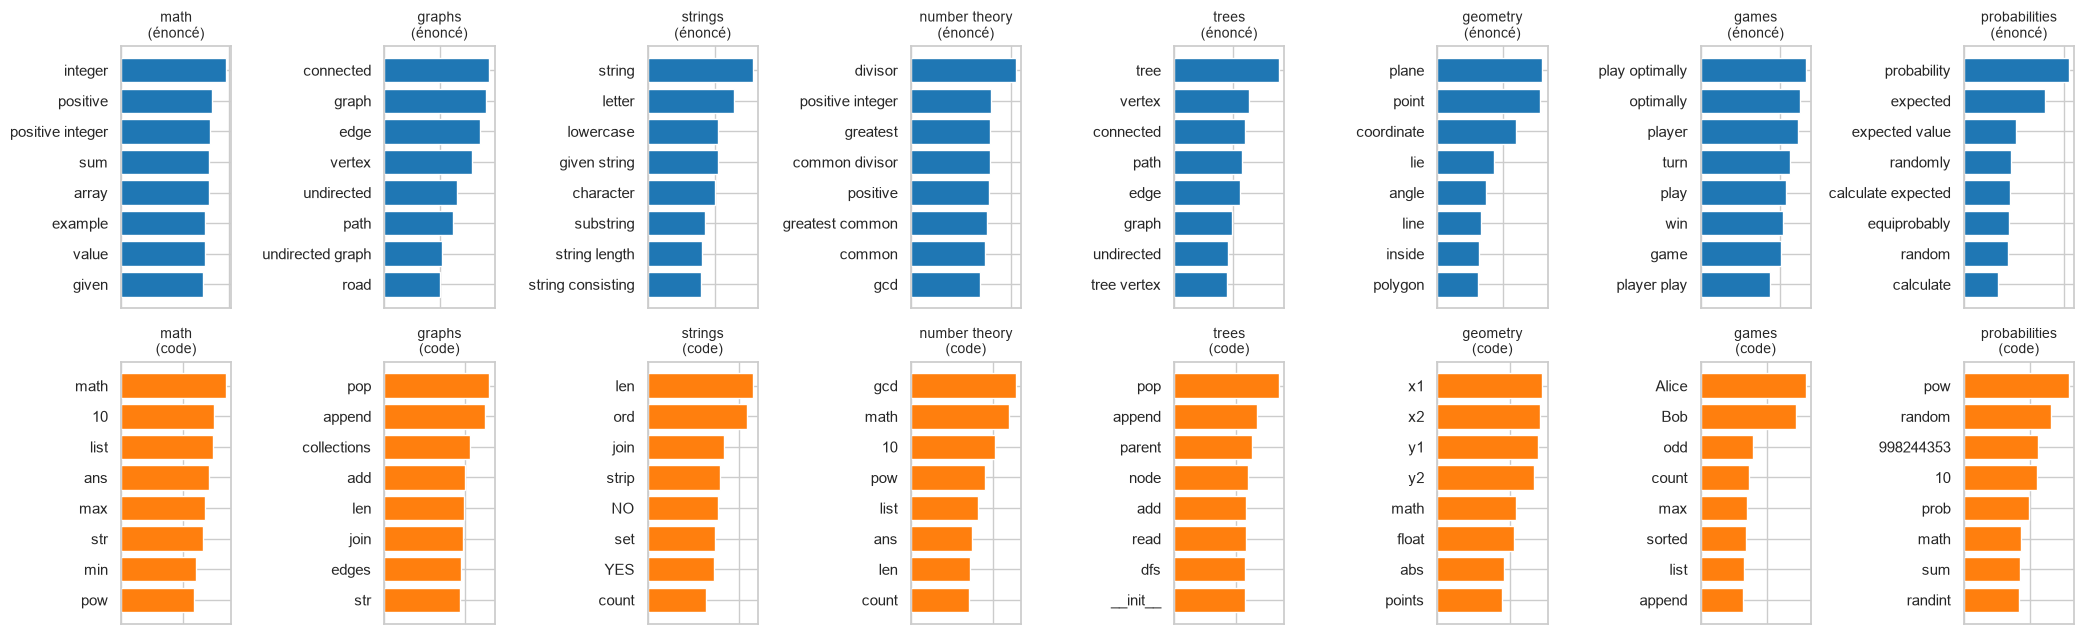

In [8]:
NO_TAG = "(aucun tag cible)"
groups = {tag: Y_train[:, k] == 1 for k, tag in enumerate(TAGS)}
groups[NO_TAG] = Y_train.sum(axis=1) == 0


def naive_tag_tfidf(texts: pd.Series) -> pd.DataFrame:
    """TF-IDF classique sur 9 « documents de tag » (textes concaténés)."""
    docs = [" ".join(texts[mask]) for mask in groups.values()]
    vectorizer = TfidfVectorizer(stop_words="english")
    scores = vectorizer.fit_transform(docs).toarray()
    return pd.DataFrame(scores, index=list(groups), columns=vectorizer.get_feature_names_out())


def tag_tfidf(texts: pd.Series, **vectorizer_args) -> pd.DataFrame:
    """Score (tag x terme) = part des exercices du tag contenant le terme × IDF globale."""
    vectorizer = CountVectorizer(min_df=5, binary=True, **vectorizer_args)
    presence = vectorizer.fit_transform(texts)
    idf = np.log(presence.shape[0] / presence.sum(axis=0).A1)
    scores = {name: presence[mask].mean(axis=0).A1 * idf for name, mask in groups.items()}
    return pd.DataFrame(scores, index=vectorizer.get_feature_names_out()).T


def top_terms(scores: pd.DataFrame, n: int = 6) -> pd.DataFrame:
    return pd.DataFrame({tag: row.nlargest(n).index.tolist() for tag, row in scores.iterrows()})


print("Version naïve (biaisée vers les mots fréquents) :")
display(top_terms(naive_tag_tfidf(train_df["text_lemma"])))

desc_scores = tag_tfidf(train_df["text_lemma"], stop_words="english", ngram_range=(1, 2))
code_scores = tag_tfidf(train_df["source_code"], token_pattern=CODE_TOKEN_PATTERN, lowercase=False, stop_words=CODE_STOP_WORDS)

fig, axes = plt.subplots(2, len(TAGS), figsize=(21, 6.5))
for row, (source, scores) in enumerate({"énoncé": desc_scores, "code": code_scores}.items()):
    for ax, tag in zip(axes[row], TAGS):
        top = scores.loc[tag].nlargest(8)[::-1]
        ax.barh(top.index, top.values, color="tab:blue" if row == 0 else "tab:orange")
        ax.set_title(f"{tag}\n({source})", fontsize=10)
        ax.tick_params(axis="x", labelbottom=False)
plt.tight_layout()
plt.show()

**Lecture**
- 7 tags sur 8 ont des marqueurs nets dans l'énoncé (`strings` → *letter* ; `games` → *play optimally* ;
  `geometry` → *point, polygon* ; `probabilities` → *probability, expected*).
- **`math` fait exception** dans l'énoncé (termes génériques), mais **le code le trahit** (`gcd`, `pow`), comme
  `probabilities` (`998244353`, le module premier des réponses modulo) ou `games` (`Alice`, `Bob`) : le code est une
  source à exploiter (section 3).

### 1.3 Sentence-BERT

La TF-IDF traite chaque mot comme une colonne indépendante : elle ne rapproche pas *chance* et *probability*, et ne
comprend pas une phrase. Un encodeur **Sentence-BERT** (`all-mpnet-base-v2`) transforme un texte entier en un vecteur
de 768 dimensions où deux textes de sens proche sont proches.

Les embeddings sont longs à calculer (environ 1 min 30 pour 4 834 énoncés) : on les met en cache sur disque.

In [9]:
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"


def cached_embeddings(texts: pd.Series, model_name: str, cache_name: str, batch_size: int = 32, max_len: int | None = None) -> np.ndarray:
    """Embeddings normalisés L2 ; relus depuis le cache s'il correspond aux mêmes exemples et au même modèle."""
    path = EMBEDDINGS_DIR / f"{model_name.split('/')[-1]}__{cache_name}.npz"
    if path.exists():
        cache = np.load(path)
        if str(cache["model"]) == model_name and np.array_equal(cache["sample_id"], texts.index):
            return cache["embeddings"]

    encoder = SentenceTransformer(model_name, device=device)
    if max_len:
        encoder.max_seq_length = max_len
    embeddings = encoder.encode(texts.tolist(), batch_size=batch_size, normalize_embeddings=True, show_progress_bar=True)
    path.parent.mkdir(parents=True, exist_ok=True)
    np.savez(path, embeddings=embeddings, sample_id=texts.index.to_numpy(), model=model_name)
    return embeddings


text_encoder = SentenceTransformer(TEXT_MODEL, device=device)
n_tokens = pd.Series([len(ids) for ids in text_encoder.tokenizer(df["text_clean"].tolist())["input_ids"]])
print(f"device={device} | longueur max={text_encoder.max_seq_length} tokens | dimension={text_encoder.get_embedding_dimension()}")
print(f"Énoncés tronqués : {(n_tokens > text_encoder.max_seq_length).mean():.1%} (médiane {n_tokens.median():.0f} tokens)")

sample = df["text_clean"].sample(256, random_state=SEED).tolist()
text_encoder.encode(sample[:32])  # échauffement
start = time.perf_counter()
text_encoder.encode(sample, batch_size=32)
print(f"Vitesse : {(time.perf_counter() - start) / len(sample) * 1000:.1f} ms par énoncé")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 13444.36it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (396 > 384). Running this sequence through the model will result in indexing errors


device=mps | longueur max=384 tokens | dimension=768
Énoncés tronqués : 2.9% (médiane 173 tokens)


Vitesse : 16.9 ms par énoncé


**Texte normalisé ou brut ?** Le nettoyage du notebook 01 (minuscules, ponctuation et LaTeX `$$$` retirés) aide la
TF-IDF, mais Sentence-BERT a été entraîné sur du texte naturel, avec sa casse et sa ponctuation. On compare les deux.

In [10]:
E = {
    "description": cached_embeddings(df["text_clean"], TEXT_MODEL, "prob_desc_description"),
    "description brute": cached_embeddings(df["prob_desc_description"], TEXT_MODEL, "prob_desc_description_raw"),
}
desc_comparison = pd.DataFrame(
    {
        "TF-IDF lemmatisée (C=1)": cv_macro_ap(tfidf_desc_model(1.0), dev("text_lemma")),
        "Sentence-BERT, texte normalisé": cv_macro_ap(logistic(), E["description"][is_dev]),
        "Sentence-BERT, texte brut": cv_macro_ap(logistic(), E["description brute"][is_dev]),
    }
).T
desc_comparison.round(4)

,cv_macro_ap,cv_std
TF-IDF lemmatisée (C=1),0.5815,0.0211
"Sentence-BERT, texte normalisé",0.5903,0.0236
"Sentence-BERT, texte brut",0.5857,0.0247


### Décision pour l'énoncé

- **TF-IDF, `C=1`** : la meilleure valeur de la grille, avec ou sans lemmatisation. Le texte non lemmatisé est un peu
  meilleur (+0,007), mais l'écart est trois fois plus petit que l'écart-type entre folds : les deux se valent. On
  garde le texte lemmatisé, déjà utilisé pour détecter les quasi-doublons au notebook 01 ; la version non lemmatisée
  reste une piste.
- **Sentence-BERT sur le texte normalisé** : texte normalisé et texte brut sont à égalité, à l'écart-type près.
- **Les deux représentations sont proches** (≈ 0,58 et 0,59) mais ne captent pas la même chose : l'une le vocabulaire
  exact (*play optimally*, *gcd*), l'autre le sens. L'embedding devient la représentation principale de l'énoncé ; la
  TF-IDF reste candidate comme source complémentaire, testée au notebook 03 avec un modèle qui sait la combiner.

## 2. Spécification d'entrée et notes

- La **spécification d'entrée** décrit le format des données : elle dit souvent la structure du problème
  (*« a tree with n vertices »*, *« a string s »*).
- Les **notes** expliquent les exemples. Elles manquent dans 27 % des exercices.

In [11]:
example = df[(df["input_spec_clean"] != "") & (df["notes_clean"] != "")].iloc[0]
print("SPÉCIFICATION D'ENTRÉE :", example["prob_desc_input_spec"][:300])
print("\nNOTES :", example["prob_desc_notes"][:300])
print(f"\nVides : spécification {(df['input_spec_clean'] == '').mean():.1%}, notes {(df['notes_clean'] == '').mean():.1%}")

SPÉCIFICATION D'ENTRÉE : The first line of the input contains one integer $$$t$$$ ($$$1 \le t \le 10^4$$$) — the number of test cases in the input. Then $$$t$$$ test cases follow. The first line of a test case contains $$$n$$$ ($$$1 \le n \le 2\cdot10^5$$$) — the number of integers in the sequence $$$a$$$. The second line c

NOTES : NoteIn the first test case of the example, the optimal sequence of moves can be as follows:  before making moves $$$a=[40, 6, 40, 3, 20, 1]$$$;  choose $$$c=6$$$;  now $$$a=[40, 3, 40, 3, 20, 1]$$$;  choose $$$c=40$$$;  now $$$a=[20, 3, 20, 3, 20, 1]$$$;  choose $$$c=20$$$;  now $$$a=[10, 3, 10, 3, 

Vides : spécification 0.7%, notes 27.1%


**Un embedding par champ, ou un seul sur le texte complet ?** Concaténer énoncé, spécification et notes avant
l'encodage est plus simple (un seul vecteur), mais Sentence-BERT tronque à 384 tokens : la fin du texte serait perdue.
On mesure la troncature, puis on compare les deux options avec l'instrument « plusieurs sources ».

Ce deuxième instrument (concaténation standardisée) a besoin d'une régularisation forte : on règle son `C` une fois,
sur toutes les sources denses étudiées dans ce notebook, puis on le garde fixe.

In [12]:
full_text = df["text_clean"] + " " + df["input_spec_clean"] + " " + df["notes_clean"]
n_full = pd.Series([len(ids) for ids in text_encoder.tokenizer(full_text.tolist())["input_ids"]])
print(f"Texte complet tronqué : {(n_full > 384).mean():.1%} (médiane {n_full.median():.0f} tokens), "
      f"contre {(n_tokens > 384).mean():.1%} pour l'énoncé seul")

E["input_spec"] = cached_embeddings(df["input_spec_clean"], TEXT_MODEL, "prob_desc_input_spec")
E["notes"] = cached_embeddings(df["notes_clean"], TEXT_MODEL, "prob_desc_notes")
E["texte complet"] = cached_embeddings(full_text, TEXT_MODEL, "full_text")
E["code"] = cached_embeddings(df["source_code"], CODE_MODEL, "source_code", batch_size=16, max_len=CODE_MAX_TOKENS)


class DifficultyEncoder(BaseEstimator, TransformerMixin):
    """One-hot de la difficulté : tranches de quantiles (apprises au fit) + une colonne « inconnue » (NaN, -1)."""

    def __init__(self, n_bins: int = DIFFICULTY_BINS):
        self.n_bins = n_bins

    def fit(self, X: np.ndarray, y=None) -> "DifficultyEncoder":
        values = X[:, 0]
        known = values[values > 0]  # NaN > 0 est faux : NaN et -1 sont exclus
        self.edges_ = np.quantile(known, np.linspace(0, 1, self.n_bins + 1)[1:-1])
        return self

    def transform(self, X: np.ndarray) -> np.ndarray:
        values = X[:, 0]
        column = np.where(values > 0, np.digitize(np.nan_to_num(values), self.edges_), self.n_bins)
        return np.eye(self.n_bins + 1)[column]


class ConcatModel(BaseEstimator):
    """Instrument « plusieurs sources » : sources concaténées → standardisation → 8 régressions logistiques."""

    def __init__(self, names: list[str], C: float = 1e-3):
        self.names, self.C = names, C

    def _features(self, sources: dict) -> np.ndarray:
        return np.hstack([self.difficulty_.transform(sources[n]) if n == "difficulty" else sources[n] for n in self.names])

    def fit(self, sources: dict, Y: np.ndarray) -> "ConcatModel":
        if "difficulty" in self.names:
            self.difficulty_ = DifficultyEncoder().fit(sources["difficulty"])
        self.model_ = make_pipeline(StandardScaler(), logistic(self.C)).fit(self._features(sources), Y)
        return self

    def predict_proba(self, sources: dict) -> np.ndarray:
        return self.model_.predict_proba(self._features(sources))


sources = {name: emb[is_dev] for name, emb in E.items()}
sources["difficulty"] = df.loc[is_dev, ["difficulty"]].to_numpy(dtype=float)

DENSE = ["description", "input_spec", "notes", "code", "difficulty"]
concat_C = pd.DataFrame({C: cv_macro_ap(ConcatModel(DENSE, C), sources) for C in (1e-4, 3e-4, 1e-3, 3e-3, 1e-2)}).T
CONCAT_C = concat_C["cv_macro_ap"].idxmax()
print("C de l'instrument « plusieurs sources » :", CONCAT_C)
concat_C.round(4)

Texte complet tronqué : 29.1% (médiane 314 tokens), contre 2.9% pour l'énoncé seul


C de l'instrument « plusieurs sources » : 0.001


,cv_macro_ap,cv_std
0.0001,0.6467,0.0350
0.0003,0.6576,0.0327
0.0010,0.6609,0.0298
0.0030,0.6544,0.0277
0.0100,0.6379,0.0242


In [13]:
def concat_cv(names: list[str]) -> pd.Series:
    return cv_macro_ap(ConcatModel(names, CONCAT_C), sources)


fields_comparison = pd.DataFrame(
    {
        "spécification seule": cv_macro_ap(logistic(), E["input_spec"][is_dev]),
        "notes seules": cv_macro_ap(logistic(), E["notes"][is_dev]),
        "énoncé seul": concat_cv(["description"]),
        "un embedding sur le texte complet": concat_cv(["texte complet"]),
        "un embedding par champ (énoncé + spécification + notes)": concat_cv(["description", "input_spec", "notes"]),
    }
).T
fields_comparison.round(4)

,cv_macro_ap,cv_std
spécification seule,0.4067,0.0284
notes seules,0.3768,0.0237
énoncé seul,0.5914,0.0246
un embedding sur le texte complet,0.6086,0.0212
un embedding par champ (énoncé + spécification + notes),0.6173,0.0240


### Décision pour la spécification et les notes

- **Seules, ces deux sources sont faibles** (≈ 0,41 et 0,37), mais elles ajoutent de l'information à l'énoncé.
- **Un embedding par champ** fait un peu mieux qu'un embedding unique sur le texte complet (+0,009, à l'écart-type
  près). Le texte complet est tronqué dans 29 % des cas, contre 3 % pour l'énoncé seul, et il mélange trois
  contenus différents dans un seul vecteur. On garde un embedding par champ.

## 3. Le code

La solution Python dit **comment** le problème a été résolu : un `gcd`, une file de priorité, une récursion sur un
arbre. Trois représentations sont comparées :

1. **TF-IDF des identifiants** : un sac de mots du code, sans les mots-clés Python ni les tokens d'entrée/sortie.
2. **Features construites à la main** : structure (lignes, profondeur d'indentation, boucles, fonctions, récursion),
   modules importés, constantes typiques (`10**9 + 7`, `998244353`), opérations bit à bit. Lisibles, mais limitées
   à ce qu'on a pensé à coder.
3. **UniXcoder** (`microsoft/unixcoder-base`) : un encodeur pré-entraîné sur du code, qui produit un vecteur de
   768 dimensions par solution.

In [14]:
IMPORTS = ["math", "collections", "heapq", "bisect", "itertools", "functools", "fractions", "random", "string", "re"]


def code_features(code: str) -> dict[str, float]:
    lines = [line for line in code.splitlines() if line.strip()]
    indents = [len(line) - len(line.lstrip()) for line in lines]

    def count(pattern: str) -> int:
        return len(re.findall(pattern, code))

    features = {
        "lignes (log)": np.log1p(len(lines)),
        "indentation max": max(indents, default=0),
        "for": np.log1p(count(r"\bfor\b")),
        "while": np.log1p(count(r"\bwhile\b")),
        "def": np.log1p(count(r"\bdef\b")),
        "setrecursionlimit": float("setrecursionlimit" in code),
        "modulo premier": float(bool(re.search(r"10\s*\*\*\s*9\s*\+\s*7|1000000007|998244353", code))),
        "bit à bit": np.log1p(count(r"<<|>>|\^")),
        "division flottante": np.log1p(count(r"[^/]/[^/]")),
    }
    for module in IMPORTS:
        features[f"import {module}"] = float(bool(re.search(rf"\b(?:import|from)\s+{module}\b", code)))
    return features


handcrafted = pd.DataFrame([code_features(code) for code in df["source_code"]], index=df.index)
# Moyenne de quelques features par tag : on y lit déjà des différences nettes
by_tag = pd.DataFrame({tag: handcrafted[Y[:, k] == 1].mean() for k, tag in enumerate(TAGS)})
by_tag["tous"] = handcrafted.mean()
display(by_tag.loc[["lignes (log)", "setrecursionlimit", "modulo premier", "bit à bit", "import math", "import heapq"]].round(2))

E["code (features à la main)"] = handcrafted.to_numpy()
sources["code (features à la main)"] = E["code (features à la main)"][is_dev]

code_tokenizer = SentenceTransformer(CODE_MODEL, device=device).tokenizer
code_tokens = pd.Series([len(ids) for ids in code_tokenizer(df["source_code"].tolist())["input_ids"]])
print(f"UniXcoder : codes tronqués à 512 tokens {(code_tokens > 512).mean():.1%}, "
      f"à 1 024 tokens {(code_tokens > 1024).mean():.1%} (médiane {code_tokens.median():.0f} tokens)")

,math,graphs,strings,number theory,trees,geometry,games,probabilities,tous
lignes (log),3.25,3.84,3.34,3.48,3.98,3.37,3.14,3.51,3.38
setrecursionlimit,0.04,0.08,0.03,0.05,0.11,0.02,0.02,0.06,0.04
modulo premier,0.13,0.08,0.12,0.18,0.11,0.05,0.06,0.28,0.09
bit à bit,0.16,0.22,0.11,0.15,0.33,0.13,0.29,0.27,0.16
import math,0.20,0.12,0.09,0.29,0.14,0.28,0.10,0.21,0.14
import heapq,0.06,0.12,0.05,0.07,0.07,0.03,0.03,0.12,0.06


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 49836.79it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1183 > 1026). Running this sequence through the model will result in indexing errors


UniXcoder : codes tronqués à 512 tokens 25.4%, à 1 024 tokens 8.8% (médiane 281 tokens)


In [15]:
tfidf_code = make_pipeline(
    TfidfVectorizer(token_pattern=CODE_TOKEN_PATTERN, lowercase=False, stop_words=CODE_STOP_WORDS, min_df=CODE_MIN_DF, sublinear_tf=True),
    logistic(0.3),  # meilleure valeur d'une grille 0,1 à 10
)
code_comparison = pd.DataFrame(
    {
        "TF-IDF des identifiants (C=0,3)": cv_macro_ap(tfidf_code, dev("source_code")),
        "features construites à la main": cv_macro_ap(make_pipeline(StandardScaler(), logistic()), sources["code (features à la main)"]),
        "UniXcoder": cv_macro_ap(logistic(), E["code"][is_dev]),
        "énoncé + UniXcoder": concat_cv(["description", "code"]),
        "énoncé + UniXcoder + features à la main": concat_cv(["description", "code", "code (features à la main)"]),
    }
).T
code_comparison.round(4)

,cv_macro_ap,cv_std
"TF-IDF des identifiants (C=0,3)",0.3191,0.0108
features construites à la main,0.1751,0.0041
UniXcoder,0.4051,0.0179
énoncé + UniXcoder,0.6541,0.0293
énoncé + UniXcoder + features à la main,0.6550,0.0289


### Décision pour le code

- **UniXcoder est la meilleure représentation du code seul**, devant la TF-IDF (les noms de variables changent d'un
  auteur à l'autre) et les features construites à la main.
- **Les features à la main n'ajoutent rien** une fois UniXcoder présent : l'encodeur capte déjà la structure et les
  modules utilisés. On ne les garde pas.
- **1 024 tokens** plutôt que 512 : 9 % des codes sont tronqués au lieu de 25 %.

## 4. La difficulté

Une cote de 800 à 3 500, inconnue pour 1 % des exercices (NaN ou `-1`). Deux encodages :
- **valeur brute** standardisée, plus un indicateur « inconnue » : suppose un effet linéaire de la difficulté ;
- **tranches** : 5 tranches de même effectif (bornes apprises sur l'entraînement) plus une tranche « inconnue », en
  one-hot. Chaque tag peut avoir sa propre relation à la difficulté, par exemple `games` fréquent à un niveau moyen.

In [16]:
difficulty = df["difficulty"].to_numpy(dtype=float)
known = difficulty > 0
sources["difficulté brute"] = np.column_stack([np.where(known, difficulty, 0.0), ~known])[is_dev]

prevalence_by_bin = pd.DataFrame(Y[known], columns=TAGS).groupby(pd.qcut(difficulty[known], DIFFICULTY_BINS), observed=True).mean()
display(prevalence_by_bin.style.format("{:.0%}").background_gradient(axis=0, cmap="Blues"))

difficulty_comparison = pd.DataFrame(
    {
        "valeur brute": cv_macro_ap(make_pipeline(StandardScaler(), logistic()), sources["difficulté brute"]),
        "tranches": cv_macro_ap(make_pipeline(DifficultyEncoder(), logistic()), sources["difficulty"]),
        "texte + code, sans difficulté": concat_cv(["description", "input_spec", "notes", "code"]),
        "texte + code + valeur brute": concat_cv(["description", "input_spec", "notes", "code", "difficulté brute"]),
        "texte + code + tranches": concat_cv(["description", "input_spec", "notes", "code", "difficulty"]),
    }
).T
difficulty_comparison.round(4)

,math,graphs,strings,number theory,trees,geometry,games,probabilities
"(799.999, 1100.0]",35%,1%,10%,5%,0%,2%,2%,0%
"(1100.0, 1500.0]",27%,6%,9%,7%,3%,1%,2%,0%
"(1500.0, 1800.0]",26%,13%,8%,7%,7%,3%,1%,2%
"(1800.0, 2200.0]",24%,18%,8%,7%,12%,4%,2%,3%
"(2200.0, 3500.0]",30%,19%,5%,9%,12%,6%,3%,6%


,cv_macro_ap,cv_std
valeur brute,0.1221,0.0059
tranches,0.1125,0.0026
"texte + code, sans difficulté",0.6594,0.0296
texte + code + valeur brute,0.6603,0.0298
texte + code + tranches,0.6609,0.0298


### Décision pour la difficulté

Seule, la difficulté prédit mal les tags (≈ 0,11, à peine au-dessus du hasard), et elle n'ajoute presque rien aux
autres sources. On la garde en **tranches** : l'apport est nul à l'écart-type près, mais elle ne coûte rien à calculer,
et la relation non linéaire entre difficulté et tags (tableau ci-dessus) peut servir à un modèle qui pondère les
sources tag par tag (notebook 03).

## 5. Les métadonnées

Restent la limite de temps, la limite de mémoire et la date de publication. On les lit dans les fichiers bruts.

In [17]:
def first_number(text: str) -> float:
    match = re.search(r"[\d.]+", str(text))
    return float(match.group()) if match else np.nan


raw = pd.DataFrame([json.loads((RAW_DIR / f"sample_{sid}.json").read_text()) for sid in df.index], index=df.index)
metadata = pd.DataFrame(
    {
        "limite de temps (s)": raw["prob_desc_time_limit"].map(first_number),
        "limite de mémoire (Mo)": np.log2(raw["prob_desc_memory_limit"].map(first_number)),
        "année": pd.to_datetime(raw["prob_desc_created_at"].astype(int), unit="s").dt.year,
    }
)
display(metadata.describe().round(1).T)
sources["métadonnées"] = metadata.fillna(metadata.median()).to_numpy()[is_dev]

metadata_comparison = pd.DataFrame(
    {
        "métadonnées seules": cv_macro_ap(make_pipeline(StandardScaler(), logistic()), sources["métadonnées"]),
        "toutes les sources retenues": concat_cv(DENSE),
        "toutes les sources retenues + métadonnées": concat_cv(DENSE + ["métadonnées"]),
    }
).T
metadata_comparison.round(4)

,count,mean,std,min,25%,50%,75%,max
limite de temps (s),4834.0,1.8,1.0,0.5,1.0,2.0,2.0,15.0
limite de mémoire (Mo),4834.0,8.0,0.4,4.0,8.0,8.0,8.0,10.0
année,4834.0,2017.6,3.5,2010.0,2015.0,2018.0,2020.0,2022.0


,cv_macro_ap,cv_std
métadonnées seules,0.1206,0.0042
toutes les sources retenues,0.6609,0.0298
toutes les sources retenues + métadonnées,0.6620,0.0298


### Décision pour les métadonnées

Les limites de temps et de mémoire valent presque toujours 1 à 2 s et 256 Mo : elles varient trop peu pour aider.
L'année ne dit rien de la technique de résolution. Leur ajout ne change pas le score : **on ne les garde pas**.

## 6. Sélection des sources : ablation

Dernière vérification sur l'ensemble : que vaut chaque source **seule**, que rapporte-t-elle quand on les **ajoute** une
à une, et que perd-on quand on la **retire** des autres ? Toujours avec l'instrument « plusieurs sources ».

Ablation en 20 s


cv_macro_ap  cv_std
type      sources                           
seule     description         0.5914  0.0246
          input_spec          0.4056  0.0270
          notes               0.3734  0.0245
          code                0.4044  0.0155
          difficulty          0.1125  0.0026
cumulatif + description       0.5914  0.0246
          + input_spec        0.6162  0.0296
          + notes             0.6173  0.0240
          + code              0.6594  0.0296
          + difficulty        0.6609  0.0298
retrait   - description       0.5749  0.0269
          - input_spec        0.6544  0.0208
          - notes             0.6608  0.0340
          - code              0.6200  0.0250
          - difficulty        0.6594  0.0296

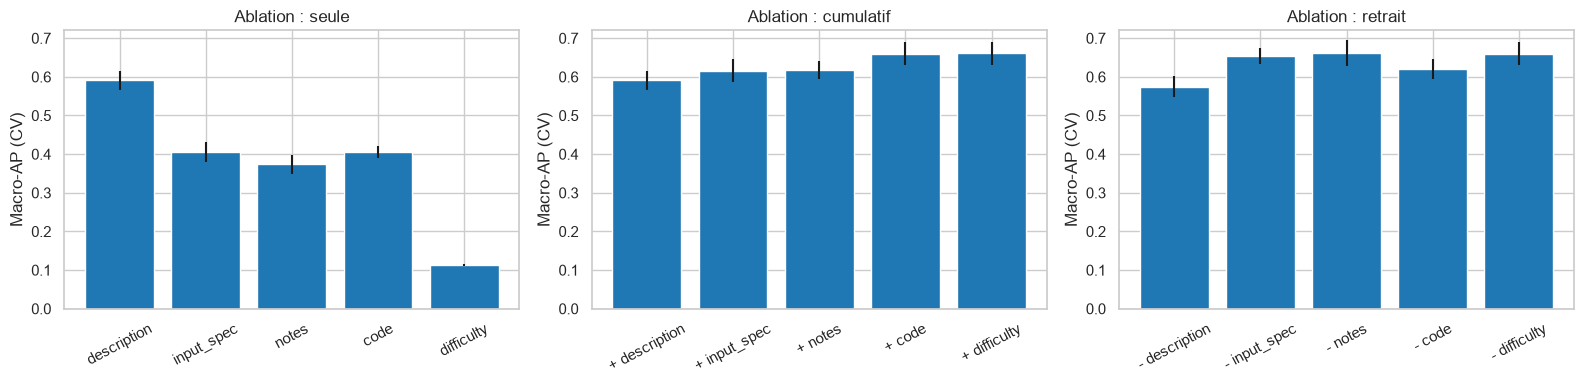

In [18]:
experiments = (
    [("seule", b, [b]) for b in DENSE]
    + [("cumulatif", "+ " + DENSE[i], DENSE[: i + 1]) for i in range(len(DENSE))]
    + [("retrait", "- " + b, [x for x in DENSE if x != b]) for b in DENSE]
)
start = time.perf_counter()
ablation = pd.DataFrame([{"type": kind, "sources": label, **concat_cv(names)} for kind, label, names in experiments])
print(f"Ablation en {time.perf_counter() - start:.0f} s")
display(ablation.set_index(["type", "sources"]).round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, kind in zip(axes, ["seule", "cumulatif", "retrait"]):
    part = ablation[ablation["type"] == kind]
    ax.bar(part["sources"], part["cv_macro_ap"], yerr=part["cv_std"], color="tab:blue")
    ax.set(title=f"Ablation : {kind}", ylim=(0, 0.72), ylabel="Macro-AP (CV)")
    ax.tick_params(axis="x", rotation=28)
plt.tight_layout()
plt.show()

## Synthèse : les entrées retenues

| Source | Représentation | Pourquoi |
|---|---|---|
| Énoncé | Sentence-BERT sur le texte normalisé | Meilleure représentation de l'énoncé (section 1) ; c'est aussi la source la plus utile (ablation) |
| Énoncé | TF-IDF lemmatisée, `C=1` | Candidate complémentaire : vocabulaire exact. Testée au notebook 03 comme source à part |
| Spécification d'entrée | Sentence-BERT, un embedding séparé | Ajoute de l'information à l'énoncé ; mieux qu'un embedding unique sur le texte complet (section 2) |
| Notes | Sentence-BERT, un embedding séparé | Apport faible, gardée car neutre ; candidate au retrait (piste) |
| Code | UniXcoder, 1 024 tokens | Deuxième source la plus utile ; meilleure que la TF-IDF et les features à la main (section 3) |
| Difficulté | 5 tranches + « inconnue » | Apport nul à l'écart-type près, coût nul ; utile si le modèle pondère par tag (section 4) |
| Métadonnées | — | Écartées : n'apportent rien (section 5) |
| TF-IDF du code | — | Écartée : moins bonne qu'UniXcoder (section 3) |

Le notebook 03 cherche maintenant **le meilleur modèle** sur ces entrées : comment les combiner, et si la TF-IDF de
l'énoncé apporte quelque chose en plus.